# J2 El Mantaro — nuestro modelo de heladas frente a GFS y ECMWF

**Pregunta.** ¿Pronostica mejor las heladas de 1 a 6 h nuestro modelo (boosting con datos de la estación, hoja y nubosidad) que la temperatura a 2 m de los dos grandes modelos globales?

| Fuente | Qué es | Resolución | Periodo usado |
|---|---|---|---|
| **nuestro modelo** | boosting entrenado con la estación, validado dejando un año fuera | puntual | 2022–2026 |
| **GFS** | NOAA/NCEP, `gfs_seamless` de Open-Meteo | ~13 km | 2022–2026 |
| **ECMWF** | IFS HRES, `ecmwf_ifs` de Open-Meteo | ~9 km | desde 2024-03 |

Los datos de GFS y ECMWF vienen de la **Historical Forecast API** de Open-Meteo, que ya ajusta la temperatura a la altitud de la estación (3314 m). El archivo de ECMWF HRES como pronóstico empieza en marzo de 2024, así que la comparación principal usa el **periodo común desde 2024-03-01**; GFS se evalúa también en todo el periodo.

**Cada modelo global se usa de tres formas:**
* **crudo**: helada si la temperatura pronosticada es ≤ 0 °C (o ≤ 2 °C);
* **corregido** (MOS): una regresión que aprende el sesgo local de cada modelo a partir de su temperatura, la hora y la época del año, validada también dejando un año fuera. Es lo mínimo que haría un servicio meteorológico antes de usar un modelo global en un punto;
* **corregido + Td**: el mismo MOS, añadiendo el **punto de rocío** pronosticado y la depresión T − Td. El aire seco favorece un enfriamiento nocturno más fuerte, así que el punto de rocío podría ayudar a corregir el sesgo cálido.

Además, la sección 7 prueba si el punto de rocío de GFS y ECMWF sirve para anticipar el **tipo de helada** (blanca o negra), que en la estación depende sobre todo de lo seco que está el aire.

**Advertencia importante: la comparación favorece a GFS y ECMWF.** La Historical Forecast API une las primeras horas de corridas sucesivas, así que el valor a una hora dada viene de una corrida iniciada pocas horas antes, sin contar el retraso real con que se publican (≈ 4–6 h). En operación, a las 22:00 solo se dispondría de una corrida más antigua. Por eso el resultado de GFS y ECMWF casi no depende del plazo.

**Verdad:** la temperatura mínima horaria de la estación (`temperatura_minima`). Las métricas (CSI, POD, FAR, BSS, AUC, MAE) son las mismas de los notebooks anteriores.

In [1]:
from pathlib import Path
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss, mean_absolute_error

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})

BASE = Path.cwd()
while not (BASE / 'data').exists() and BASE != BASE.parent:
    BASE = BASE.parent
DATA = BASE / 'data' / 'processed'
EXT = BASE / 'data' / 'external'
OUT = BASE / 'resultados'; OUT.mkdir(exist_ok=True)

EST = 'j2_el_mantaro'
LAT, LON = -11.833526, -75.389548
UMBRALES = {'meteorologica': 0.0, 'agronomica': 2.0}
LEADS = list(range(1, 7))
LEADS_EVAL = [1, 3, 6, 'alerta6']
HORAS_EMISION = list(range(15, 24)) + list(range(0, 8))
UMB_MOJADO = 10
UMB_HIELO = 10
P_ALERTA = 0.5
N_BOOT = 1000
SEED = 42
rng = np.random.default_rng(SEED)
NUB_COLS = ['cloud_cover', 'cloud_cover_low', 'cloud_cover_mid', 'cloud_cover_high']
INICIO_COMUN = pd.Timestamp('2024-03-01')

## 1. Datos de la estación y variables de nuestro modelo

Código copiado del notebook de nubosidad: misma muestra y mismos 65 predictores.

In [2]:
URL_HIST = ('https://historical-forecast-api.open-meteo.com/v1/forecast?latitude={lat}&longitude={lon}'
            '&start_date={a}&end_date={b}&hourly=' + ','.join(NUB_COLS) + '&timezone=America%2FLima')

def descargar_nubosidad_hist(a, b, lat=LAT, lon=LON):
    j = json.load(urllib.request.urlopen(URL_HIST.format(lat=lat, lon=lon, a=a, b=b), timeout=120))
    df = pd.DataFrame(j['hourly']).rename(columns={'time': 'fecha'})
    df['fecha'] = pd.to_datetime(df['fecha'])
    return df.set_index('fecha')

CACHE = EXT / 'openmeteo_nubosidad_j2_el_mantaro.csv'
if CACHE.exists():
    NUB = pd.read_csv(CACHE, parse_dates=['fecha']).set_index('fecha')
else:
    NUB = pd.concat([descargar_nubosidad_hist(f'{y}-01-01', f'{y}-12-31') for y in range(2022, 2027)])
    NUB.reset_index().to_csv(CACHE, index=False)
print(NUB.index.min(), '->', NUB.index.max(), '| faltantes:', NUB.isna().sum().sum())
NUB.describe().round(1)

2022-03-01 00:00:00 -> 2026-10-31 23:00:00 | faltantes: 0


,cloud_cover,cloud_cover_low,cloud_cover_mid,cloud_cover_high
count,40944.0,40944.0,40944.0,40944.0
mean,66.5,27.3,32.9,48.9
std,37.1,33.2,33.7,43.3
min,0.0,0.0,0.0,0.0
25%,33.0,1.0,3.0,0.0
50%,85.0,13.0,21.0,47.0
75%,100.0,40.0,54.0,98.0
max,100.0,100.0,100.0,100.0


In [3]:
meta = pd.read_csv(DATA / 'estaciones.csv').set_index('estacion')
REN = {'temperatura_media': 'T', 'temperatura_minima': 'Tmin', 'temperatura_maxima': 'Tmax',
       'punto_rocio_medio': 'Td', 'humedad_media': 'HR', 'velocidad_viento_medio_1h': 'viento',
       'velocidad_viento_maximo_1h': 'viento_max', 'precipitacion_acc_1h': 'pp',
       'radiacion_solar_media_1h': 'rad', 'rh_hoja_arriba_media_1h': 'arriba',
       'rh_hoja_bajo_media_1h': 'bajo', 'suelo_temperatura_5cm': 'Tsuelo5'}

def preparar(d):
    d = d.copy()
    if 'fecha' in d: d = d.set_index('fecha')
    d = d.rename(columns=REN)
    for c in REN.values():
        if c not in d: d[c] = np.nan
    return d[list(REN.values())].asfreq('h')

def var_meteo(d):
    X = pd.DataFrame(index=d.index)
    for c in ['T', 'Tmin', 'Tmax', 'Td', 'HR', 'viento', 'viento_max', 'rad', 'Tsuelo5']:
        X[c] = d[c]
    X['dep'] = d['T'] - d['Td']
    for k in (1, 3, 6):
        X[f'dT_{k}h'] = d['T'] - d['T'].shift(k)
    X['dTd_3h'] = d['Td'] - d['Td'].shift(3)
    X['dHR_3h'] = d['HR'] - d['HR'].shift(3)
    X['viento_3h'] = d['viento'].rolling(3, min_periods=2).mean()
    X['pp_3h'] = d['pp'].rolling(3, min_periods=1).sum()
    X['pp_24h'] = d['pp'].rolling(24, min_periods=12).sum()
    X['Tmax_12h'] = d['Tmax'].rolling(12, min_periods=8).max()
    X['amplitud_12h'] = X['Tmax_12h'] - d['T']
    X['Tmin_24h'] = d['Tmin'].rolling(24, min_periods=12).min()
    rad24 = d['rad'].rolling(24, min_periods=18).sum()
    X['claridad_24h'] = rad24 / rad24.rolling('60D', min_periods=24 * 20).quantile(.95)
    X['suelo_menos_aire'] = d['Tsuelo5'] - d['T']
    h, doy = d.index.hour, d.index.dayofyear
    X['hora_sin'], X['hora_cos'] = np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24)
    X['doy_sin'], X['doy_cos'] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
    return X

def linea_base_hoja(d):
    seco = d.index.hour.isin(range(11, 16)) & (d['pp'].fillna(0) == 0) & (d['HR'] < 60)
    rel = {}
    for k in ('arriba', 'bajo'):
        base = d[k].where(seco).rolling('30D', min_periods=20).median().shift(1).ffill()
        rel[k] = d[k] - base
    return rel

def var_hoja(d):
    X = pd.DataFrame(index=d.index)
    noche = (d.index - pd.Timedelta(hours=12)).normalize()
    rel = linea_base_hoja(d)
    for k in ('arriba', 'bajo'):
        r = rel[k]
        X[f'{k}_rel'] = r
        for L in (1, 3):
            X[f'{k}_d{L}h'] = r - r.shift(L)
        X[f'{k}_max3h'] = r.rolling(3, min_periods=2).max()
        moj = (r > UMB_MOJADO).astype(float).where(r.notna())
        X[f'{k}_horas_mojado'] = moj.fillna(0).groupby(noche).cumsum()
    X['arriba_menos_bajo'] = X['arriba_rel'] - X['bajo_rel']
    X['mojado_y_dep'] = X['arriba_rel'] / (1 + (d['T'] - d['Td']).clip(lower=0))
    return X

def var_nub(nub, idx, leads=LEADS):
    # nubosidad pronosticada en t y en las horas de validez t+1..t+6
    n = nub.reindex(idx)
    X = pd.DataFrame(index=idx)
    for c in NUB_COLS:
        X[f'{c}_t'] = n[c]
        fut = pd.concat([n[c].shift(-k) for k in leads], axis=1)
        X[f'{c}_med6h'] = fut.mean(axis=1)
        X[f'{c}_min6h'] = fut.min(axis=1)
    for k in leads:
        X[f'cc_t+{k}'] = n['cloud_cover'].shift(-k)
        X[f'ccl_t+{k}'] = n['cloud_cover_low'].shift(-k)
    X['cc_tendencia'] = n['cloud_cover'].shift(-6) - n['cloud_cover']
    X['cc_previa_6h'] = n['cloud_cover'].rolling(6, min_periods=3).mean()
    return X

D = preparar(pd.read_csv(DATA / 'horario' / f'{EST}.csv', parse_dates=['fecha']))
XM, XH, XN = var_meteo(D), var_hoja(D), var_nub(NUB, D.index)
F_METEO, F_HOJA, F_NUB = list(XM.columns), list(XH.columns), list(XN.columns)
ALL = XM.join(XH).join(XN)
for k in LEADS:
    ALL[f'y_T_{k}'] = D['Tmin'].shift(-k)
ALL['y_T_alerta6'] = pd.concat([D['Tmin'].shift(-k) for k in LEADS], axis=1).min(axis=1, skipna=False)
ALL['noche'] = (D.index - pd.Timedelta(hours=12)).normalize()
ALL['anio'] = D.index.year
print(len(F_METEO), 'meteo |', len(F_HOJA), 'hoja |', len(F_NUB), 'nubosidad')

27 meteo | 12 hoja | 26 nubosidad


In [4]:
MUESTRA = ALL[ALL.index.hour.isin(HORAS_EMISION) & ALL['T'].notna() & ALL['Tmin'].notna()
              & ALL['arriba_rel'].notna() & ALL['bajo_rel'].notna() & ALL['cloud_cover_t'].notna()].copy()
FEATS = F_METEO + F_HOJA + F_NUB
ANIOS = sorted(MUESTRA['anio'].unique())
print(len(MUESTRA), 'horas de emisión |', len(FEATS), 'predictores | años', ANIOS)

26451 horas de emisión | 65 predictores | años [2022, 2023, 2024, 2025, 2026]


## 2. Temperatura y punto de rocío pronosticados por GFS y ECMWF

Se descargan una vez de Open-Meteo y se guardan en `data/external/`.

In [5]:
URL_NWP = ('https://historical-forecast-api.open-meteo.com/v1/forecast?latitude={lat}&longitude={lon}'
           '&start_date={a}&end_date={b}&hourly=temperature_2m,dew_point_2m&models={m}&timezone=America%2FLima')
MODELOS_NWP = {'GFS': ('gfs_seamless', '2022-03-01'), 'ECMWF': ('ecmwf_ifs', str(INICIO_COMUN.date()))}
FIN = '2026-10-31'

def descargar_nwp(modelo, inicio, fin=FIN):
    partes = []
    for y in range(pd.Timestamp(inicio).year, pd.Timestamp(fin).year + 1):
        a = max(pd.Timestamp(inicio), pd.Timestamp(f'{y}-01-01')).date()
        b = min(pd.Timestamp(fin), pd.Timestamp(f'{y}-12-31')).date()
        j = json.load(urllib.request.urlopen(URL_NWP.format(lat=LAT, lon=LON, a=a, b=b, m=modelo), timeout=180))
        partes.append(pd.DataFrame(j['hourly']))
    df = pd.concat(partes).rename(columns={'time': 'fecha'})
    df['fecha'] = pd.to_datetime(df['fecha'])
    return df.set_index('fecha')[['temperature_2m', 'dew_point_2m']]

NWP, NWP_TD = {}, {}
for nom, (modelo, inicio) in MODELOS_NWP.items():
    cache = EXT / f'openmeteo_{modelo}_t_td_j2_el_mantaro.csv'
    if cache.exists():
        df = pd.read_csv(cache, parse_dates=['fecha']).set_index('fecha')
    else:
        df = descargar_nwp(modelo, inicio)
        df.reset_index().to_csv(cache, index=False)
    NWP[nom], NWP_TD[nom] = df['temperature_2m'], df['dew_point_2m']
    print(f'{nom}: {df.index.min()} -> {df.index.max()} | T: {df.temperature_2m.notna().sum()} h | '
          f'Td: {df.dew_point_2m.notna().sum()} h')
NWP, NWP_TD = pd.DataFrame(NWP), pd.DataFrame(NWP_TD)

GFS: 2022-03-01 00:00:00 -> 2026-10-31 23:00:00 | T: 40944 h | Td: 40944 h


ECMWF: 2024-03-01 00:00:00 -> 2026-10-31 23:00:00 | T: 23400 h | Td: 23400 h


### 2.1 Sesgo de los modelos globales frente a la estación

Diferencia media *modelo − estación* por hora del día, en el periodo común, para la temperatura media horaria y para las noches frías.

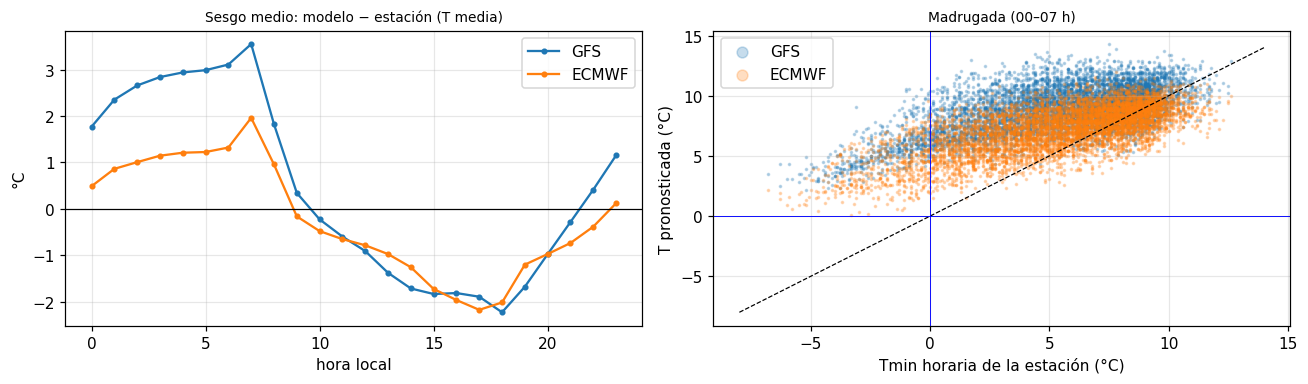

,GFS,ECMWF
"sesgo T media, todas las horas",0.43,-0.22
"sesgo frente a Tmin, 00–07 h",3.36,1.73
"sesgo frente a Tmin, horas con helada",7.43,5.87
horas con helada en la estación (00–07 h),530.00,530.00
"de ellas, con T del modelo ≤ 0 °C",0.00,0.00


In [6]:
comun = NWP.join(D[['T', 'Tmin']], how='inner')
comun = comun[(comun.index >= INICIO_COMUN) & comun[['GFS', 'ECMWF', 'T']].notna().all(axis=1)]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
for nom in NWP:
    (comun[nom] - comun['T']).groupby(comun.index.hour).mean().plot(ax=axs[0], marker='o', ms=3, label=nom)
axs[0].axhline(0, color='k', lw=.8); axs[0].set_xlabel('hora local'); axs[0].set_ylabel('°C')
axs[0].set_title('Sesgo medio: modelo − estación (T media)', fontsize=9); axs[0].legend()
noche = comun[comun.index.hour.isin(range(0, 8))]
for nom in NWP:
    axs[1].scatter(noche['Tmin'], noche[nom], s=2, alpha=.25, label=nom)
axs[1].plot([-8, 14], [-8, 14], 'k--', lw=.8); axs[1].axvline(0, color='b', lw=.6); axs[1].axhline(0, color='b', lw=.6)
axs[1].set_xlabel('Tmin horaria de la estación (°C)'); axs[1].set_ylabel('T pronosticada (°C)')
axs[1].set_title('Madrugada (00–07 h)', fontsize=9); axs[1].legend(markerscale=5)
plt.tight_layout(); plt.show()
pd.DataFrame({nom: {'sesgo T media, todas las horas': (comun[nom] - comun['T']).mean(),
                    'sesgo frente a Tmin, 00–07 h': (noche[nom] - noche['Tmin']).mean(),
                    'sesgo frente a Tmin, horas con helada': (noche.loc[noche.Tmin <= 0, nom] - noche.loc[noche.Tmin <= 0, 'Tmin']).mean(),
                    'horas con helada en la estación (00–07 h)': int((noche.Tmin <= 0).sum()),
                    'de ellas, con T del modelo ≤ 0 °C': int(((noche.Tmin <= 0) & (noche[nom] <= 0)).sum())}
              for nom in NWP}).round(2)

### 2.2 Punto de rocío: sesgo frente a la estación

Misma comparación para el punto de rocío (Td). La sección 7 lo separa por tipo de helada.

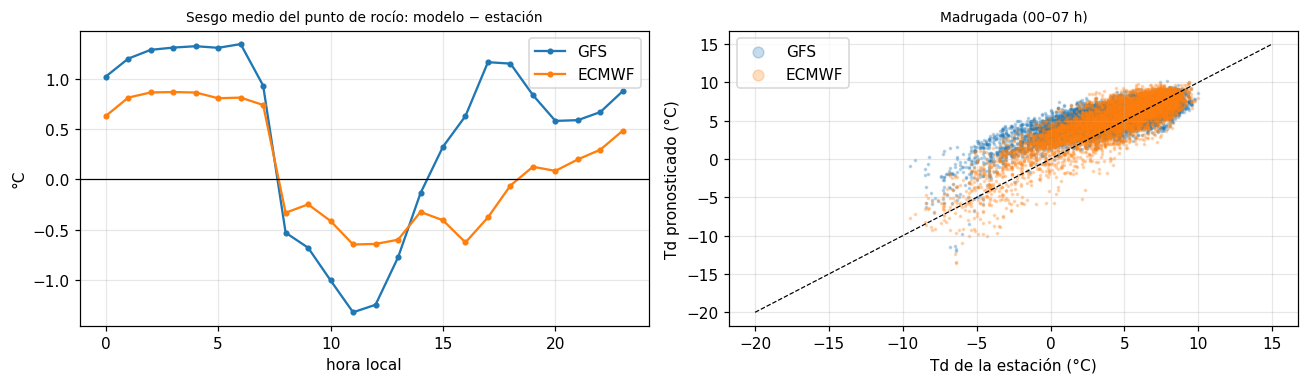

,GFS,ECMWF
"sesgo Td, todas las horas",0.45,0.12
"sesgo Td, 00–07 h",1.22,0.80
"MAE Td, 00–07 h",1.85,1.51
"correlación Td, 00–07 h",0.80,0.85


In [7]:
comun_td = NWP_TD.join(D[['Td']], how='inner')
comun_td = comun_td[(comun_td.index >= INICIO_COMUN) & comun_td[['GFS', 'ECMWF', 'Td']].notna().all(axis=1)]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
for nom in NWP_TD:
    (comun_td[nom] - comun_td['Td']).groupby(comun_td.index.hour).mean().plot(ax=axs[0], marker='o', ms=3, label=nom)
axs[0].axhline(0, color='k', lw=.8); axs[0].set_xlabel('hora local'); axs[0].set_ylabel('°C')
axs[0].set_title('Sesgo medio del punto de rocío: modelo − estación', fontsize=9); axs[0].legend()
noche_td = comun_td[comun_td.index.hour.isin(range(0, 8))]
for nom in NWP_TD:
    axs[1].scatter(noche_td['Td'], noche_td[nom], s=2, alpha=.25, label=nom)
axs[1].plot([-20, 15], [-20, 15], 'k--', lw=.8)
axs[1].set_xlabel('Td de la estación (°C)'); axs[1].set_ylabel('Td pronosticado (°C)')
axs[1].set_title('Madrugada (00–07 h)', fontsize=9); axs[1].legend(markerscale=5)
plt.tight_layout(); plt.show()
pd.DataFrame({nom: {'sesgo Td, todas las horas': (comun_td[nom] - comun_td['Td']).mean(),
                    'sesgo Td, 00–07 h': (noche_td[nom] - noche_td['Td']).mean(),
                    'MAE Td, 00–07 h': (noche_td[nom] - noche_td['Td']).abs().mean(),
                    'correlación Td, 00–07 h': noche_td[[nom, 'Td']].corr().iloc[0, 1]}
              for nom in NWP_TD}).round(2)

## 3. Pronósticos fuera de muestra

Para cada plazo y cada hora de emisión *t*:
* **nuestro modelo**: probabilidad de helada (0 °C y 2 °C) y Tmin del boosting, entrenados dejando un año fuera (la misma configuración del modelo operativo);
* **GFS / ECMWF crudo**: la temperatura pronosticada a la hora *t+h* (para la alerta de 6 h, la mínima entre *t+1* y *t+6*);
* **GFS / ECMWF corregido**: una regresión lineal (Tmin) y una logística (probabilidad) con la temperatura del modelo, la hora y la época del año, también dejando un año fuera;
* **GFS / ECMWF corregido + Td**: lo mismo, añadiendo el punto de rocío del modelo y la depresión T − Td a la hora *t+h* (para la alerta de 6 h, la media de Td entre *t+1* y *t+6*).

In [8]:
def boosting_clf():
    return HistGradientBoostingClassifier(max_iter=500, learning_rate=0.04, max_leaf_nodes=31, min_samples_leaf=40,
                                          l2_regularization=1.0, early_stopping=True, validation_fraction=0.15,
                                          random_state=SEED)
def boosting_reg():
    return HistGradientBoostingRegressor(max_iter=500, learning_rate=0.04, max_leaf_nodes=31, min_samples_leaf=40,
                                         l2_regularization=1.0, early_stopping=True, validation_fraction=0.15,
                                         random_state=SEED)

def nwp_valido(idx, lead, nom, tabla=None, agg='min'):
    s = (NWP if tabla is None else tabla)[nom]
    if lead == 'alerta6':
        v = pd.concat([s.reindex(idx + pd.Timedelta(hours=k)).set_axis(idx) for k in LEADS], axis=1)
        return v.min(axis=1, skipna=False) if agg == 'min' else v.mean(axis=1, skipna=False)
    return s.reindex(idx + pd.Timedelta(hours=lead)).set_axis(idx)

def x_mos(t_nwp, idx, lead, td_nwp=None):
    v = idx + pd.Timedelta(hours=6 if lead == 'alerta6' else lead)
    h, doy = v.hour, v.dayofyear
    X = pd.DataFrame({'T': t_nwp.values, 'hs': np.sin(2 * np.pi * h / 24), 'hc': np.cos(2 * np.pi * h / 24),
                      'ds': np.sin(2 * np.pi * doy / 365.25), 'dc': np.cos(2 * np.pi * doy / 365.25)}, index=idx)
    if td_nwp is not None:
        X['Td'] = td_nwp.values
        X['dep'] = X['T'] - X['Td']
    return X

PRED = {}
for lead in LEADS_EVAL:
    col = f'y_T_{lead}'
    sub = MUESTRA[MUESTRA[col].notna()]
    r = sub[['noche', 'anio', 'Tmin', col]].rename(columns={col: 'y_T'}).copy()
    for nom_u, u in UMBRALES.items():
        y = sub[col] <= u
        for a in ANIOS:
            tr, te = sub['anio'] != a, sub['anio'] == a
            r.loc[te, f'p_modelo_{nom_u}'] = boosting_clf().fit(sub.loc[tr, FEATS], y[tr]).predict_proba(sub.loc[te, FEATS])[:, 1]
    if lead != 'alerta6':
        for a in ANIOS:
            tr, te = sub['anio'] != a, sub['anio'] == a
            r.loc[te, 'T_modelo'] = boosting_reg().fit(sub.loc[tr, FEATS], sub.loc[tr, col]).predict(sub.loc[te, FEATS])
    for nom in NWP:
        t_nwp = nwp_valido(sub.index, lead, nom)
        td_nwp = nwp_valido(sub.index, lead, nom, tabla=NWP_TD, agg='mean')
        r[f'T_{nom}_crudo'] = t_nwp
        ok = t_nwp.notna() & td_nwp.notna()
        for var, X in (('corregido', x_mos(t_nwp[ok], sub.index[ok], lead)),
                       ('corregido_td', x_mos(t_nwp[ok], sub.index[ok], lead, td_nwp[ok]))):
            for a in sorted(sub.loc[ok, 'anio'].unique()):
                tr = (sub.loc[ok, 'anio'] != a).values; te = ~tr
                if tr.sum() == 0: continue
                idx_te = X.index[te]
                r.loc[idx_te, f'T_{nom}_{var}'] = LinearRegression().fit(X[tr], sub.loc[ok, col][tr]).predict(X[te])
                for nom_u, u in UMBRALES.items():
                    yb = (sub.loc[ok, col] <= u)[tr]
                    r.loc[idx_te, f'p_{nom}_{var}_{nom_u}'] = LogisticRegression(max_iter=3000).fit(X[tr], yb).predict_proba(X[te])[:, 1]
        for nom_u, u in UMBRALES.items():
            r[f'p_{nom}_crudo_{nom_u}'] = (t_nwp <= u).astype(float).where(ok)
    PRED[lead] = r
    print('listo: plazo', lead)

listo: plazo 1


listo: plazo 3


listo: plazo 6


listo: plazo alerta6


## 4. Probabilidad de helada: métricas en el periodo común (desde 2024-03)

Solo se usan las horas en que las tres fuentes tienen pronóstico. *inicio*: horas en que todavía no helaba en *t*.

In [9]:
FUENTES = ['modelo', 'GFS_crudo', 'GFS_corregido', 'GFS_corregido_td', 'ECMWF_crudo', 'ECMWF_corregido', 'ECMWF_corregido_td']
NOMBRE = {'modelo': 'nuestro modelo', 'GFS_crudo': 'GFS crudo', 'GFS_corregido': 'GFS corregido',
          'GFS_corregido_td': 'GFS corregido + Td', 'ECMWF_crudo': 'ECMWF crudo',
          'ECMWF_corregido': 'ECMWF corregido', 'ECMWF_corregido_td': 'ECMWF corregido + Td'}

def csi(y, yh):
    a = (y & yh).sum(); b = (~y & yh).sum(); c = (y & ~yh).sum()
    return a / max(a + c, 1), b / max(a + b, 1), a / max(a + b + c, 1)

def tabla(nom_u, u, desde=INICIO_COMUN, fuentes=FUENTES):
    filas = []
    for lead, r in PRED.items():
        cols = [f'p_{f}_{nom_u}' for f in fuentes]
        t0 = r[(r.index >= desde) & r[cols].notna().all(axis=1)]
        for casos in ('todos', 'inicio'):
            t = t0 if casos == 'todos' else t0[t0['Tmin'] > u]
            y = (t['y_T'] <= u).values
            bsc = brier_score_loss(y, np.full(len(y), y.mean()))
            for f in fuentes:
                p = t[f'p_{f}_{nom_u}'].values
                score = -t[f'T_{f}'].values if f.endswith('crudo') else p
                pod, far, c = csi(y, p >= P_ALERTA)
                filas.append({'umbral': nom_u, 'plazo': str(lead), 'casos': casos, 'fuente': NOMBRE[f],
                              'n_horas': len(y), 'n_eventos': int(y.sum()), 'POD': pod, 'FAR': far, 'CSI': c,
                              'BSS': 1 - brier_score_loss(y, p) / bsc, 'AUC': roc_auc_score(y, score)})
    return pd.DataFrame(filas)

MET = pd.concat([tabla(nom_u, u) for nom_u, u in UMBRALES.items()])
MET.to_csv(OUT / 'el_mantaro_vs_gfs_ecmwf_metricas.csv', index=False)
ORDEN = [NOMBRE[f] for f in FUENTES]
MET[MET.casos == 'todos'].pivot_table(index=['umbral', 'plazo'], columns='fuente', values=['CSI', 'POD', 'FAR'],
                                      sort=False)[[(k, f) for k in ('CSI', 'POD', 'FAR') for f in ORDEN]].round(3)

CSI                                                                                                        POD                                             \
fuente                nuestro modelo GFS crudo GFS corregido GFS corregido + Td ECMWF crudo ECMWF corregido ECMWF corregido + Td nuestro modelo GFS crudo GFS corregido GFS corregido + Td   
umbral        plazo                                                                                                                                                                          
meteorologica 1                0.882       0.0         0.499              0.557       0.000           0.391                0.510          0.934       0.0         0.642              0.697   
              3                0.792       0.0         0.496              0.536       0.000           0.394                0.502          0.884       0.0         0.637              0.676   
              6                0.699       0.0         0.499              0.534       0.000           0.397                0.511          0.791       0.0         0.640              0.673   
              alerta6          0.750       0.0         0.517              0.544       0.000           0.414                0.511          0.839       0.0         0.664              0.686   
agronomica    1                0.891       0.0         0.503              0.520       0.054           0.435                0.537          0.934       0.0         0.645              0.660   
              3                0.776       0.0         0.497              0.513       0.054           0.434                0.516          0.879       0.0         0.635              0.653   
              6                0.667       0.0         0.498              0.511       0.054           0.435                0.521          0.773       0.0         0.635              0.650   
              alerta6          0.764       0.0         0.530              0.560       0.087           0.475                0.566          0.853       0.0         0.684              0.711   

                                                                                  FAR                                                                                              
fuente                ECMWF crudo ECMWF corregido ECMWF corregido + Td nuestro modelo GFS crudo GFS corregido GFS corregido + Td ECMWF crudo ECMWF corregido ECMWF corregido + Td  
umbral        plazo                                                                                                                                                                
meteorologica 1             0.000           0.471                0.578          0.059       0.0         0.308              0.266         0.0           0.301                0.187  
              3             0.000           0.476                0.578          0.116       0.0         0.308              0.280         0.0           0.304                0.207  
              6             0.000           0.478                0.588          0.143       0.0         0.306              0.278         0.0           0.299                0.204  
              alerta6       0.000           0.501                0.585          0.123       0.0         0.299              0.277         0.0           0.297                0.197  
agronomica    1             0.054           0.542                0.640          0.049       0.0         0.305              0.290         0.0           0.312                0.231  
              3             0.054           0.541                0.617          0.131       0.0         0.304              0.295         0.0           0.312                0.242  
              6             0.054           0.542                0.624          0.171       0.0         0.303              0.296         0.0           0.311                0.240  
              alerta6       0.087           0.591                0.677          0.120       0.0         0.299              0.275         0.0  

In [10]:
MET.pivot_table(index=['umbral', 'casos', 'plazo'], columns='fuente', values=['BSS', 'AUC'],
                sort=False)[[(k, f) for k in ('BSS', 'AUC') for f in ORDEN]].round(3)

BSS                                                                                                        AUC                                             \
fuente                       nuestro modelo GFS crudo GFS corregido GFS corregido + Td ECMWF crudo ECMWF corregido ECMWF corregido + Td nuestro modelo GFS crudo GFS corregido GFS corregido + Td   
umbral        casos  plazo                                                                                                                                                                          
meteorologica todos  1                0.904    -0.040         0.518              0.579      -0.040           0.407                0.553          0.998     0.955         0.978              0.986   
                     3                0.825    -0.040         0.514              0.557      -0.040           0.404                0.532          0.998     0.954         0.977              0.984   
                     6                0.733    -0.040         0.514              0.557      -0.040           0.404                0.535          0.995     0.956         0.978              0.984   
                     alerta6          0.773    -0.085         0.511              0.554      -0.085           0.401                0.549          0.994     0.928         0.960              0.972   
              inicio 1                0.606    -0.008        -0.469             -0.328      -0.008          -0.374               -0.128          0.993     0.938         0.960              0.972   
                     3                0.715    -0.022         0.244              0.329      -0.022           0.173                0.319          0.997     0.944         0.967              0.977   
                     6                0.698    -0.035         0.466              0.523      -0.035           0.362                0.501          0.995     0.955         0.975              0.982   
                     alerta6          0.651    -0.053         0.331              0.383      -0.053           0.229                0.401          0.991     0.925         0.952              0.965   
agronomica    todos  1                0.904    -0.093         0.506              0.535      -0.034           0.440                0.578          0.999     0.903         0.966              0.972   
                     3                0.787    -0.093         0.499              0.515      -0.034           0.434                0.542          0.994     0.902         0.964              0.969   
                     6                0.698    -0.093         0.500              0.515      -0.034           0.433                0.543          0.989     0.909         0.964              0.969   
                     alerta6          0.766    -0.190         0.500              0.527      -0.087           0.442                0.569          0.989     0.864         0.943              0.952   
              inicio 1                0.620    -0.017        -0.596             -0.518      -0.017          -0.489               -0.232          0.996     0.870         0.938              0.947   
                     3                0.649    -0.047         0.217              0.259      -0.039           0.176                0.321          0.992     0.878         0.952              0.959   
                     6                0.648    -0.081         0.429              0.455      -0.045           0.361                0.492          0.986     0.895         0.958              0.964   
                     alerta6          0.630    -0.108         0.306              0.341      -0.070           0.251                0.410          0.982     0.858         0.932              0.940   

                                                                               
fuente                       ECMWF crudo ECMWF corregido ECMWF corregido + Td  
umbral        casos  plazo                                                     
meteorologica todos  1             0.950           0.959

In [11]:
MET[MET.casos == 'inicio'].pivot_table(index=['umbral', 'plazo'], columns='fuente', values=['CSI', 'POD', 'FAR'],
                                       sort=False)[[(k, f) for k in ('CSI', 'POD', 'FAR') for f in ORDEN]].round(3)

CSI                                                                                                        POD                                             \
fuente                nuestro modelo GFS crudo GFS corregido GFS corregido + Td ECMWF crudo ECMWF corregido ECMWF corregido + Td nuestro modelo GFS crudo GFS corregido GFS corregido + Td   
umbral        plazo                                                                                                                                                                          
meteorologica 1                0.570       0.0         0.117              0.166       0.000           0.110                0.155          0.711       0.0         0.273              0.347   
              3                0.667       0.0         0.312              0.373       0.000           0.261                0.336          0.791       0.0         0.475              0.532   
              6                0.662       0.0         0.460              0.498       0.000           0.373                0.479          0.759       0.0         0.610              0.637   
              alerta6          0.626       0.0         0.391              0.416       0.000           0.308                0.389          0.741       0.0         0.570              0.590   
agronomica    1                0.589       0.0         0.114              0.122       0.000           0.113                0.154          0.704       0.0         0.283              0.291   
              3                0.640       0.0         0.315              0.335       0.008           0.273                0.340          0.779       0.0         0.482              0.501   
              6                0.616       0.0         0.447              0.460       0.034           0.383                0.472          0.730       0.0         0.597              0.604   
              alerta6          0.627       0.0         0.398              0.429       0.034           0.344                0.426          0.749       0.0         0.601              0.629   

                                                                                  FAR                                                                                              
fuente                ECMWF crudo ECMWF corregido ECMWF corregido + Td nuestro modelo GFS crudo GFS corregido GFS corregido + Td ECMWF crudo ECMWF corregido ECMWF corregido + Td  
umbral        plazo                                                                                                                                                                
meteorologica 1             0.000           0.215                0.248          0.259       0.0         0.829              0.759         0.0           0.816                0.709  
              3             0.000           0.361                0.418          0.191       0.0         0.522              0.446         0.0           0.513                0.368  
              6             0.000           0.462                0.554          0.162       0.0         0.349              0.303         0.0           0.339                0.220  
              alerta6       0.000           0.413                0.477          0.199       0.0         0.446              0.414         0.0           0.453                0.322  
agronomica    1             0.000           0.257                0.304          0.217       0.0         0.840              0.826         0.0           0.833                0.764  
              3             0.008           0.400                0.454          0.218       0.0         0.524              0.498         0.0           0.538                0.425  
              6             0.034           0.496                0.574          0.203       0.0         0.358              0.342         0.0           0.374                0.275  
              alerta6       0.034           0.491                0.568          0.207       0.0         0.460              0.425         0.0  

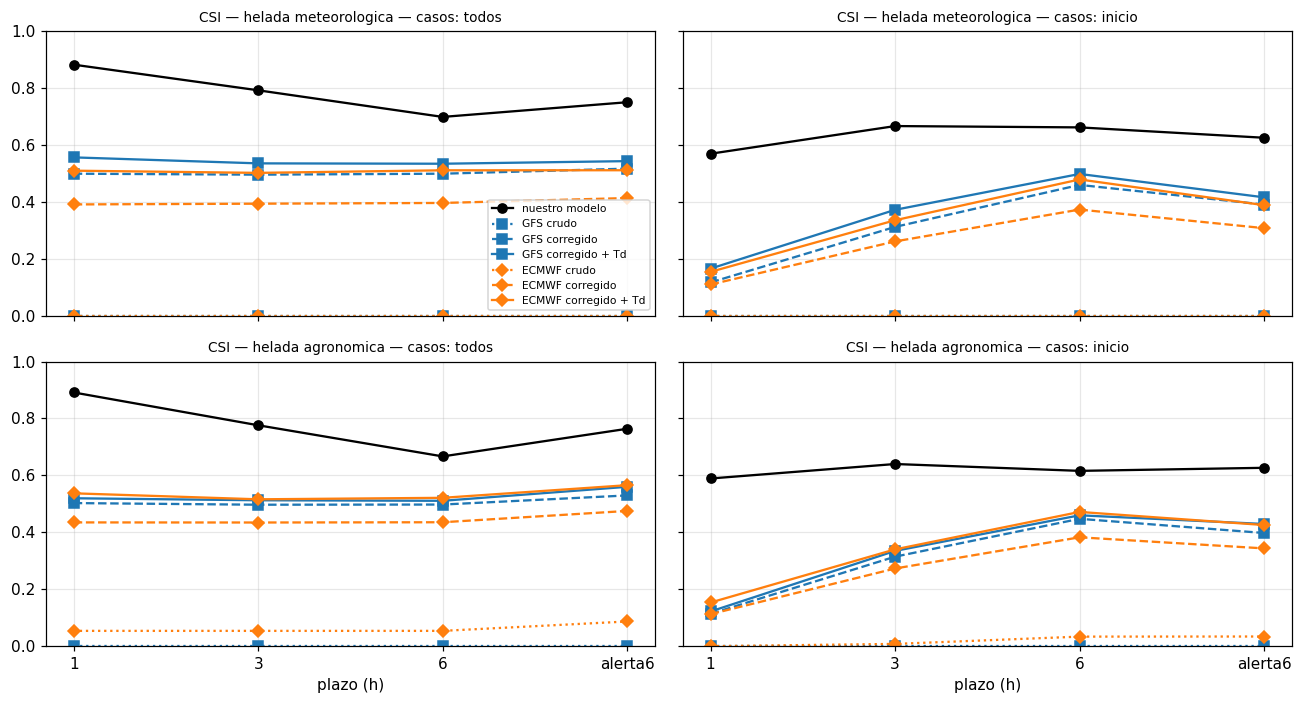

In [12]:
fig, axs = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True, sharey=True)
orden = [str(l) for l in LEADS_EVAL]
estilo = {'nuestro modelo': ('k', 'o', '-'), 'GFS crudo': ('tab:blue', 's', ':'), 'GFS corregido': ('tab:blue', 's', '--'),
          'GFS corregido + Td': ('tab:blue', 's', '-'), 'ECMWF crudo': ('tab:orange', 'D', ':'),
          'ECMWF corregido': ('tab:orange', 'D', '--'), 'ECMWF corregido + Td': ('tab:orange', 'D', '-')}
for i, nom_u in enumerate(UMBRALES):
    for j, casos in enumerate(('todos', 'inicio')):
        ax = axs[i, j]
        for f, (c, mk, ls) in estilo.items():
            g = MET[(MET.umbral == nom_u) & (MET.casos == casos) & (MET.fuente == f)].set_index('plazo').loc[orden]
            ax.plot(orden, g['CSI'], color=c, marker=mk, ls=ls, label=f)
        ax.set_title(f'CSI — helada {nom_u} — casos: {casos}', fontsize=9); ax.set_ylim(0, 1)
axs[0, 0].legend(fontsize=7)
for ax in axs[-1]: ax.set_xlabel('plazo (h)')
plt.tight_layout(); plt.show()

### 4.1 Diferencia de nuestro modelo frente a cada fuente (bootstrap por noche)

Positivo: **nuestro modelo es mejor**. *mejor* / *peor* solo si el intervalo al 95 % no incluye 0.

In [13]:
def boot_diff(t, pa, pb, u):
    y = (t['y_T'] <= u).astype(float)
    cols = {'n': 1.0, 'y': y, 'se_a': (t[pa] - y) ** 2, 'se_b': (t[pb] - y) ** 2}
    for s, c in (('a', pa), ('b', pb)):
        al = t[c] >= P_ALERTA; yy = y.astype(bool)
        cols[f'h_{s}'], cols[f'f_{s}'], cols[f'm_{s}'] = yy & al, ~yy & al, yy & ~al
    g = pd.DataFrame(cols, index=t.index).astype(float).groupby(t['noche']).sum()
    S = pd.DataFrame(rng.multinomial(len(g), np.ones(len(g)) / len(g), size=N_BOOT) @ g.values, columns=g.columns)
    clim = S['y'] / S['n']; bsc = (S['y'] * (1 - clim) ** 2 + (S['n'] - S['y']) * clim ** 2) / S['n']
    dbss = (S['se_b'] - S['se_a']) / S['n'] / bsc
    dcsi = S['h_a'] / (S['h_a'] + S['f_a'] + S['m_a']) - S['h_b'] / (S['h_b'] + S['f_b'] + S['m_b'])
    return dbss, dcsi

ic = lambda s: f'{s.median():+.3f} [{s.quantile(.025):+.3f}, {s.quantile(.975):+.3f}]'
sig = lambda s: 'mejor' if s.quantile(.025) > 0 else 'peor' if s.quantile(.975) < 0 else 'igual'
filas = []
for nom_u, u in UMBRALES.items():
    for lead, r in PRED.items():
        cols = [f'p_{f}_{nom_u}' for f in FUENTES]
        t0 = r[(r.index >= INICIO_COMUN) & r[cols].notna().all(axis=1)]
        for casos in ('todos', 'inicio'):
            t = t0 if casos == 'todos' else t0[t0['Tmin'] > u]
            for f in FUENTES[1:]:
                dbss, dcsi = boot_diff(t, f'p_modelo_{nom_u}', f'p_{f}_{nom_u}', u)
                filas.append({'umbral': nom_u, 'plazo': str(lead), 'casos': casos, 'frente a': NOMBRE[f],
                              'ΔCSI': ic(dcsi), 'CSI': sig(dcsi), 'ΔBSS': ic(dbss), 'BSS': sig(dbss)})
BOOT = pd.DataFrame(filas)
BOOT.to_csv(OUT / 'el_mantaro_vs_gfs_ecmwf_bootstrap.csv', index=False)
BOOT[BOOT.casos == 'todos'].pivot_table(index=['umbral', 'plazo'], columns='frente a', values='ΔCSI',
                                        aggfunc='first', sort=False)[ORDEN[1:]]

frente a                             GFS crudo            GFS corregido       GFS corregido + Td              ECMWF crudo          ECMWF corregido     ECMWF corregido + Td
umbral        plazo                                                                                                                                                        
meteorologica 1        +0.882 [+0.851, +0.906]  +0.384 [+0.330, +0.441]  +0.325 [+0.271, +0.387]  +0.882 [+0.856, +0.907]  +0.493 [+0.431, +0.551]  +0.373 [+0.313, +0.435]
              3        +0.792 [+0.750, +0.829]  +0.295 [+0.245, +0.348]  +0.256 [+0.209, +0.309]  +0.792 [+0.752, +0.828]  +0.395 [+0.326, +0.461]  +0.289 [+0.233, +0.349]
              6        +0.700 [+0.646, +0.750]  +0.198 [+0.146, +0.254]  +0.163 [+0.112, +0.213]  +0.699 [+0.646, +0.743]  +0.299 [+0.224, +0.376]  +0.189 [+0.125, +0.258]
              alerta6  +0.750 [+0.704, +0.795]  +0.233 [+0.180, +0.288]  +0.205 [+0.154, +0.262]  +0.751 [+0.704, +0.794]  +0.337 [+0.271, +0.406]  +0.239 [+0.180, +0.295]
agronomica    1        +0.891 [+0.871, +0.908]  +0.389 [+0.349, +0.427]  +0.373 [+0.333, +0.415]  +0.838 [+0.808, +0.863]  +0.456 [+0.413, +0.502]  +0.355 [+0.318, +0.396]
              3        +0.777 [+0.747, +0.805]  +0.279 [+0.240, +0.317]  +0.264 [+0.227, +0.302]  +0.723 [+0.687, +0.756]  +0.341 [+0.296, +0.389]  +0.260 [+0.221, +0.297]
              6        +0.666 [+0.625, +0.705]  +0.171 [+0.127, +0.211]  +0.156 [+0.115, +0.196]  +0.613 [+0.571, +0.654]  +0.232 [+0.177, +0.282]  +0.144 [+0.103, +0.190]
              alerta6  +0.765 [+0.734, +0.792]  +0.235 [+0.197, +0.275]  +0.205 [+0.166, +0.244]  +0.678 [+0.639, +0.716]  +0.288 [+0.242, +0.333]  +0.199 [+0.160, +0.238]

In [14]:
# Resumen sobre las 16 combinaciones (umbral × plazo × casos)
pd.concat({k: BOOT.groupby('frente a')[k].value_counts().unstack(fill_value=0) for k in ('CSI', 'BSS')}, axis=1).loc[ORDEN[1:]]

,CSI,BSS
CSI,mejor,mejor
frente a,,
GFS crudo,16,16
GFS corregido,16,16
GFS corregido + Td,16,16
ECMWF crudo,16,16
ECMWF corregido,16,16
ECMWF corregido + Td,16,16


## 5. Temperatura mínima pronosticada

Error absoluto medio (MAE) y sesgo (pronóstico − observado) de la Tmin horaria, en el periodo común.

In [15]:
filas = []
for lead in [1, 3, 6]:
    r = PRED[lead]
    cols = ['T_modelo'] + [f'T_{f}' for f in FUENTES[1:]]
    t0 = r[(r.index >= INICIO_COMUN) & r[cols].notna().all(axis=1)]
    for casos, t in (('todas', t0), ('noches frías (Tmin ≤ 3 °C)', t0[t0['y_T'] <= 3])):
        for f in FUENTES:
            e = t[f'T_{f}'] - t['y_T']
            filas.append({'plazo': lead, 'casos': casos, 'fuente': NOMBRE[f], 'MAE': e.abs().mean(), 'sesgo': e.mean()})
TM = pd.DataFrame(filas)
TM.to_csv(OUT / 'el_mantaro_vs_gfs_ecmwf_tmin.csv', index=False)
TM.pivot_table(index=['casos', 'plazo'], columns='fuente', values=['MAE', 'sesgo'], sort=False)[
    [(k, f) for k in ('MAE', 'sesgo') for f in ORDEN]].round(2)

MAE                                                                                                      sesgo                                             \
fuente                           nuestro modelo GFS crudo GFS corregido GFS corregido + Td ECMWF crudo ECMWF corregido ECMWF corregido + Td nuestro modelo GFS crudo GFS corregido GFS corregido + Td   
casos                      plazo                                                                                                                                                                        
todas                      1               0.58      2.74          1.88               1.87        2.03            1.73                 1.70          -0.01      1.84         -0.16              -0.15   
                           3               0.98      2.73          1.77               1.76        1.98            1.63                 1.57          -0.01      2.10         -0.17              -0.15   
                           6               1.17      2.70          1.68               1.68        1.99            1.60                 1.53          -0.04      2.31         -0.19              -0.18   
noches frías (Tmin ≤ 3 °C) 1               0.33      6.66          2.47               2.43        4.93            2.50                 2.28           0.09      6.66          2.39               2.35   
                           3               0.75      6.66          2.47               2.39        4.93            2.55                 2.26           0.50      6.66          2.40               2.31   
                           6               1.13      6.66          2.36               2.30        4.93            2.56                 2.26           0.84      6.66          2.26               2.19   

                                                                                   
fuente                           ECMWF crudo ECMWF corregido ECMWF corregido + Td  
casos                      plazo                                                   
todas                      1            0.90            0.01                -0.00  
                           3            1.15            0.01                -0.00  
                           6            1.35            0.02                -0.00  
noches frías (Tmin ≤ 3 °C) 1            4.93            2.27                 1.97  
                           3            4.93            2.36                 2.02  
                           6            4.93            2.38                 1.98

## 6. Ejemplos de noches con helada (fuera de muestra)

Tmin observada, temperatura cruda de GFS y ECMWF, y la Tmin de nuestro modelo emitida 3 h antes de cada hora.

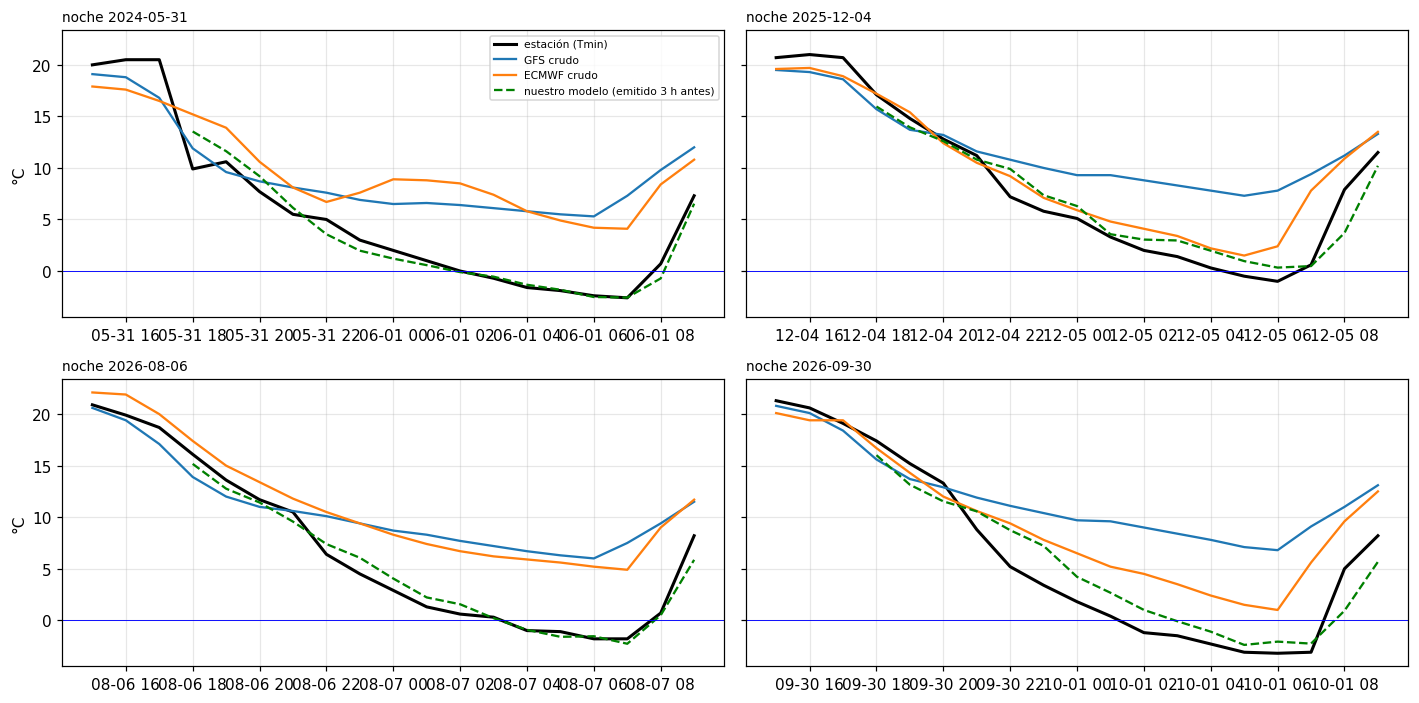

In [16]:
r3 = PRED[3]
noches_h = (r3[(r3.index >= INICIO_COMUN) & (r3['y_T'] <= 0)].index + pd.Timedelta(hours=3) - pd.Timedelta(hours=12)).normalize().unique()
ej = pd.Series(noches_h).sample(4, random_state=3).sort_values()
fig, axs = plt.subplots(2, 2, figsize=(13, 6.5), sharey=True)
for ax, n in zip(axs.flat, ej):
    ini, fin = n + pd.Timedelta(hours=15), n + pd.Timedelta(hours=33)
    ax.plot(D.loc[ini:fin].index, D.loc[ini:fin, 'Tmin'], 'k-', lw=2, label='estación (Tmin)')
    for nom, c in (('GFS', 'tab:blue'), ('ECMWF', 'tab:orange')):
        ax.plot(NWP.loc[ini:fin].index, NWP.loc[ini:fin, nom], color=c, label=f'{nom} crudo')
    m = r3.loc[ini - pd.Timedelta(hours=3):fin - pd.Timedelta(hours=3), 'T_modelo']
    ax.plot(m.index + pd.Timedelta(hours=3), m.values, 'g--', label='nuestro modelo (emitido 3 h antes)')
    ax.axhline(0, color='b', lw=.6); ax.set_title(f'noche {n:%Y-%m-%d}', fontsize=9, loc='left')
axs[0, 0].legend(fontsize=7); axs[0, 0].set_ylabel('°C'); axs[1, 0].set_ylabel('°C')
plt.tight_layout(); plt.show()

## 7. Tipo de helada: ¿sirve el punto de rocío de GFS y ECMWF?

En la estación, lo que mejor anticipa si una helada será **negra** es lo seco que está el aire (punto de rocío bajo). Aquí se compara, para cada noche con helada clasificada por el sensor de hoja, la capacidad de distinguir negras de blancas (**AUC**) de:

* el **punto de rocío y la depresión T − Td de la estación a las 18 h**, lo que se sabe al anochecer;
* el **punto de rocío y la depresión T − Td pronosticados por GFS y ECMWF** para la noche (media de 19 a 06 h).

AUC 0.5 es azar y 1 es perfecto. El intervalo al 95 % se obtiene remuestreando noches. Con pocas heladas negras, los intervalos son amplios.

In [17]:
REL = linea_base_hoja(D)
noche_s = ALL['noche']
h = D.index.hour
es_noche = (h >= 18) | (h <= 8)
fh = D[es_noche & (D['Tmin'] <= 0)].copy()
fh['senal'] = pd.concat([REL['arriba'], REL['bajo']], axis=1).max(axis=1).reindex(fh.index)
fh['noche'] = noche_s.reindex(fh.index)
fh['dep'] = fh['T'] - fh['Td']
NOCH = fh.groupby('noche').agg(horas_bajo0=('Tmin', 'size'), tmin=('Tmin', 'min'), senal_max=('senal', 'max'),
                               senal_med=('senal', 'median'), dep_med=('dep', 'median'), hr_max=('HR', 'max'),
                               td_min=('Td', 'min'), viento=('viento', 'mean'))
nub_noche = NUB.reindex(D.index[es_noche]).groupby(noche_s.reindex(D.index[es_noche])).mean()
NOCH = NOCH.join(nub_noche)
NOCH['tipo_hoja'] = np.select([NOCH['senal_max'].isna(), NOCH['senal_max'] >= UMB_HIELO], ['sin dato', 'blanca'], 'negra')
# heurística de Td (primer notebook), en la hora de la Tmin
idx_min = fh.groupby('noche')['Tmin'].idxmin()
td_m, dep_m = D.loc[idx_min.values, 'Td'].values, (D['T'] - D['Td']).loc[idx_min.values].values
NOCH['tipo_td'] = np.where((td_m <= 0) & (dep_m <= 3), 'blanca', 'negra')
print(NOCH['tipo_hoja'].value_counts())
pd.crosstab(NOCH['tipo_hoja'], NOCH['tipo_td'], margins=True)

tipo_hoja
blanca    244
negra      24
Name: count, dtype: int64


tipo_td,blanca,negra,All
tipo_hoja,,,
blanca,229,15,244
negra,16,8,24
All,245,23,268


In [18]:
P = NOCH[NOCH.tipo_hoja.isin(['blanca', 'negra'])][['tipo_hoja', 'tmin']].copy()
P['negra'] = P['tipo_hoja'] == 'negra'
n_idx = P.index
ventana = range(19, 31)   # 19:00 a 06:00 de la noche
def media_ventana(s):
    return np.nanmean(np.column_stack([s.reindex(n_idx + pd.Timedelta(hours=h)).values for h in ventana]), axis=1)
P['Td estación 18 h'] = D['Td'].reindex(n_idx + pd.Timedelta(hours=18)).values
P['T−Td estación 18 h'] = (D['T'] - D['Td']).reindex(n_idx + pd.Timedelta(hours=18)).values
P['Td estación noche (observado)'] = media_ventana(D['Td'])
for nom in NWP:
    P[f'Td {nom} noche'] = media_ventana(NWP_TD[nom])
    P[f'T−Td {nom} noche'] = media_ventana(NWP[nom]) - P[f'Td {nom} noche']

def auc_ic(y, s):
    y, s = np.asarray(y), np.asarray(s)
    out = []
    for _ in range(N_BOOT):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            out.append(roc_auc_score(y[i], s[i]))
    return roc_auc_score(y, s), np.quantile(out, .025), np.quantile(out, .975)

VARS_TIPO = ['Td estación 18 h', 'T−Td estación 18 h', 'Td GFS noche', 'T−Td GFS noche', 'Td ECMWF noche', 'T−Td ECMWF noche']
filas = []
for periodo, desde, vs in (('común (desde 2024-03)', INICIO_COMUN, VARS_TIPO),
                           ('2022–2026 (sin ECMWF)', pd.Timestamp('2022-01-01'), [v for v in VARS_TIPO if 'ECMWF' not in v])):
    t = P[(P.index >= desde)].dropna(subset=vs)
    for v in vs:
        score = -t[v] if v.startswith('Td') else t[v]      # Td bajo o T−Td alto -> más probable que sea negra
        a, lo, hi = auc_ic(t['negra'], score)
        filas.append({'periodo': periodo, 'variable': v, 'noches': len(t), 'negras': int(t['negra'].sum()),
                      'AUC': round(a, 3), 'IC 95 %': f'[{lo:.3f}, {hi:.3f}]'})
AUC_TIPO = pd.DataFrame(filas)
AUC_TIPO.to_csv(OUT / 'el_mantaro_vs_gfs_ecmwf_tipo_helada.csv', index=False)
AUC_TIPO

/tmp/ipykernel_51432/4259905237.py:6: RuntimeWarning: Mean of empty slice
  return np.nanmean(np.column_stack([s.reindex(n_idx + pd.Timedelta(hours=h)).values for h in ventana]), axis=1)
/tmp/ipykernel_51432/4259905237.py:6: RuntimeWarning: Mean of empty slice
  return np.nanmean(np.column_stack([s.reindex(n_idx + pd.Timedelta(hours=h)).values for h in ventana]), axis=1)


,periodo,variable,noches,negras,AUC,IC 95 %
0,común (desde 2024-03),Td estación 18 h,121,15,0.889,"[0.815, 0.953]"
1,común (desde 2024-03),T−Td estación 18 h,121,15,0.879,"[0.788, 0.949]"
2,común (desde 2024-03),Td GFS noche,121,15,0.816,"[0.691, 0.913]"
3,común (desde 2024-03),T−Td GFS noche,121,15,0.806,"[0.673, 0.922]"
4,común (desde 2024-03),Td ECMWF noche,121,15,0.842,"[0.725, 0.930]"
5,común (desde 2024-03),T−Td ECMWF noche,121,15,0.881,"[0.802, 0.947]"
6,2022–2026 (sin ECMWF),Td estación 18 h,268,24,0.878,"[0.812, 0.937]"
7,2022–2026 (sin ECMWF),T−Td estación 18 h,268,24,0.868,"[0.799, 0.925]"
8,2022–2026 (sin ECMWF),Td GFS noche,268,24,0.793,"[0.674, 0.892]"
9,2022–2026 (sin ECMWF),T−Td GFS noche,268,24,0.798,"[0.696, 0.887]"


In [19]:
# ¿Cuánto se equivocan GFS y ECMWF en el punto de rocío de las noches con helada, según el tipo?
t = P[P.index >= INICIO_COMUN].dropna(subset=['Td GFS noche', 'Td ECMWF noche', 'Td estación noche (observado)'])
pd.DataFrame({nom: t.groupby('tipo_hoja').apply(lambda g: (g[f'Td {nom} noche'] - g['Td estación noche (observado)']).mean())
              for nom in NWP}).rename_axis('sesgo medio de Td (modelo − estación), °C').round(2)

,GFS,ECMWF
"sesgo medio de Td (modelo − estación), °C",,
blanca,3.49,1.21
negra,4.99,0.98


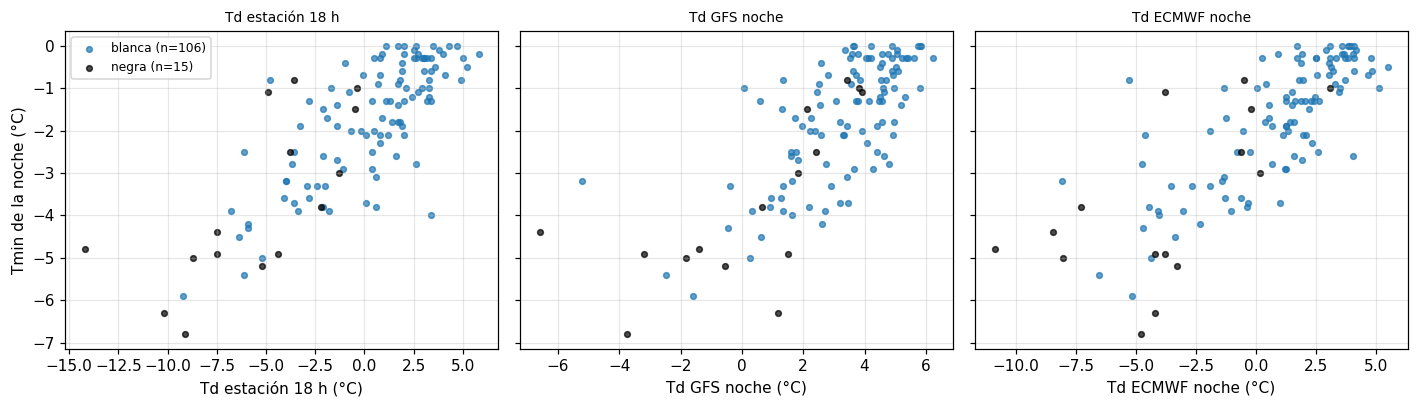

In [20]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
t = P[P.index >= INICIO_COMUN]
for ax, v in zip(axs, ['Td estación 18 h', 'Td GFS noche', 'Td ECMWF noche']):
    for tipo, c in (('blanca', 'tab:blue'), ('negra', 'k')):
        s = t[t.tipo_hoja == tipo]
        ax.scatter(s[v], s['tmin'], s=14, color=c, alpha=.7, label=f'{tipo} (n={s[v].notna().sum()})')
    ax.set_xlabel(f'{v} (°C)'); ax.set_title(v, fontsize=9)
axs[0].set_ylabel('Tmin de la noche (°C)'); axs[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 8. GFS en todo el periodo (2022–2026)

Como GFS tiene archivo desde 2021, se repite la comparación de CSI con GFS en todos los años, sin ECMWF.

In [21]:
F_GFS = ['modelo', 'GFS_crudo', 'GFS_corregido', 'GFS_corregido_td']
MET_GFS = pd.concat([tabla(nom_u, u, desde=pd.Timestamp('2022-01-01'), fuentes=F_GFS) for nom_u, u in UMBRALES.items()])
MET_GFS.to_csv(OUT / 'el_mantaro_vs_gfs_2022_2026_metricas.csv', index=False)
MET_GFS.pivot_table(index=['umbral', 'casos', 'plazo'], columns='fuente', values=['CSI', 'BSS'], sort=False)[
    [(k, NOMBRE[f]) for k in ('CSI', 'BSS') for f in F_GFS]].round(3)

CSI                                                       BSS                                           
fuente                       nuestro modelo GFS crudo GFS corregido GFS corregido + Td nuestro modelo GFS crudo GFS corregido GFS corregido + Td
umbral        casos  plazo                                                                                                                      
meteorologica todos  1                0.889       0.0         0.490              0.524          0.911    -0.053         0.536              0.572
                     3                0.793       0.0         0.486              0.510          0.828    -0.053         0.531              0.555
                     6                0.712       0.0         0.488              0.509          0.743    -0.053         0.532              0.556
                     alerta6          0.778       0.0         0.516              0.540          0.792    -0.113         0.535              0.565
              inicio 1                0.571       0.0         0.140              0.162          0.637    -0.011        -0.283             -0.192
                     3                0.676       0.0         0.316              0.353          0.727    -0.029         0.310              0.361
                     6                0.684       0.0         0.466              0.487          0.714    -0.048         0.503              0.533
                     alerta6          0.657       0.0         0.396              0.416          0.676    -0.068         0.385              0.416
agronomica    todos  1                0.887       0.0         0.522              0.530          0.901    -0.115         0.540              0.558
                     3                0.777       0.0         0.514              0.524          0.790    -0.115         0.533              0.542
                     6                0.694       0.0         0.515              0.523          0.717    -0.115         0.533              0.543
                     alerta6          0.774       0.0         0.544              0.569          0.772    -0.238         0.525              0.547
              inicio 1                0.560       0.0         0.125              0.130          0.595    -0.020        -0.366             -0.314
                     3                0.635       0.0         0.318              0.333          0.649    -0.057         0.281              0.310
                     6                0.643       0.0         0.467              0.476          0.666    -0.100         0.472              0.489
                     alerta6          0.639       0.0         0.408              0.433          0.645    -0.134         0.364              0.391

## 9. Conclusiones

**GFS y ECMWF, tal cual, no ven las heladas de El Mantaro.**

* En el periodo común (marzo 2024 – octubre 2026) la estación registró **530 horas de madrugada con helada**; ni GFS ni ECMWF pronosticaron 0 °C o menos en **ninguna** de ellas. Su CSI crudo es 0 con el umbral de 0 °C, y apenas 0.05–0.09 (ECMWF) con el de 2 °C.
* El motivo es un **sesgo cálido nocturno** muy grande: en las horas con helada, GFS pronostica en promedio **7.4 °C** más que la Tmin de la estación y ECMWF **5.9 °C** más. De día el sesgo se invierte (−2 °C a las 15–18 h). Una celda de 9–13 km no representa el aire frío que se acumula de noche en el fondo del valle, aunque Open-Meteo ajuste la temperatura a la altitud de la estación.

**El punto de rocío de los modelos es mucho mejor que su temperatura.**

* De madrugada, el Td de ECMWF tiene un sesgo de solo **+0.8 °C** (GFS +1.2 °C) y una correlación de 0.85 (GFS 0.80) con la estación: la humedad del aire la representan razonablemente; lo que falla es el enfriamiento del valle.
* Añadirlo a la corrección (**corregido + Td**) mejora a los dos modelos, sobre todo a ECMWF: a 6 h, CSI 0.51 frente a 0.40 y BSS 0.54 frente a 0.40 (helada 0 °C). ECMWF corregido + Td queda cerca de GFS corregido + Td (CSI 0.50–0.51 frente a 0.53–0.56), y su Tmin en noches frías mejora de 2.5 a 2.0 °C de error.

**Aun así, nuestro modelo sigue muy por delante.**

| CSI, helada 0 °C, todos los casos | 1 h | 3 h | 6 h | alerta 6 h |
|---|---|---|---|---|
| nuestro modelo | 0.88 | 0.79 | 0.70 | 0.75 |
| GFS corregido + Td | 0.56 | 0.54 | 0.53 | 0.54 |
| ECMWF corregido + Td | 0.51 | 0.50 | 0.51 | 0.51 |
| GFS corregido | 0.50 | 0.50 | 0.50 | 0.52 |
| ECMWF corregido | 0.39 | 0.39 | 0.40 | 0.41 |

* Nuestro modelo es **significativamente mejor en las 16 combinaciones** (umbral × plazo × casos), en CSI y en BSS, frente a las seis versiones de GFS y ECMWF. Frente a la mejor (GFS corregido + Td) la ventaja en CSI va de +0.16 a 6 h a +0.37 a 1 h.
* En la **Tmin**, nuestro modelo tiene un error medio de 0.6–1.2 °C; los modelos globales corregidos, 1.5–1.9 °C, y en noches frías 2.0–2.5 °C con un sesgo cálido de +2 °C.
* La ventaja de nuestro modelo **se reduce con el plazo**, mientras GFS y ECMWF se mantienen constantes. Esto es en parte un artefacto favorable a ellos: el archivo usa siempre la corrida más reciente, sin el retraso real de publicación.
* El resultado se repite con GFS en todo el periodo 2022–2026 (sección 8).

**Tipo de helada: el punto de rocío de ECMWF casi iguala al de la estación.**

* Para distinguir heladas negras de blancas, la depresión **T − Td pronosticada por ECMWF para la noche** tiene un AUC de **0.88**, igual que el punto de rocío de la estación a las 18 h (0.89) y la depresión de la estación (0.88). GFS queda algo por detrás (0.80–0.82).
* GFS tiene un sesgo húmedo mayor justo en las noches negras (+5.0 °C en Td frente a +3.5 °C en las blancas): no capta bien las noches de aire muy seco. ECMWF no muestra ese problema (+1.0 y +1.2 °C).
* Con solo 15 noches negras en el periodo común, los intervalos son amplios (≈ ±0.1 de AUC), así que la igualdad es aproximada.
* Esto es útil: ECMWF podría **anticipar el tipo de helada con más horas de antelación** que la estación, que solo lo sabe al anochecer.

**Qué significa.** Para heladas de 1 a 6 h en un punto como J2, los datos de la propia estación valen mucho más que un modelo global: ven el enfriamiento que ya está ocurriendo, la humedad real y el aire frío del valle. Los modelos globales aportan lo que la estación no puede saber de antemano: la **nubosidad** que viene (que nuestro modelo ya usa) y, según este análisis, la **sequedad del aire** de la noche siguiente, sobre todo ECMWF.

**Siguientes pasos posibles.**
1. Añadir la temperatura y el punto de rocío de ECMWF (y GFS) como predictores del boosting.
2. Extender el pronóstico a **12–24 h**, donde la estación sola pierde capacidad y el modelo global aporta la evolución sinóptica.
3. Probar el Td de ECMWF como predictor del **tipo de helada** emitido por la tarde.

*Advertencias:* el MOS es lineal y sencillo; una corrección no lineal podría mejorar algo más a GFS y ECMWF. ECMWF solo cubre 2024–2026, con pocas temporadas para su corrección y pocas heladas negras.
